# Tarea 3 Predicción de abandono de clientes con Spark ML
**Adrian Rojas Rivera · Cédula 117550336 · Modalidad individual**

El objetivo es comparar regresión logística y bosque aleatorio para predecir `etiqueta`: 0 significa que el cliente permanece y 1 que abandona. El notebook ejecuta de principio a fin la carga, limpieza, almacenamiento en PostgreSQL, relectura, exploración, estandarización, validación cruzada y evaluación final. Se ejecuta completo con los archivos incluidos y los dos servicios de `docker-compose.yaml`.

Sigo el ejemplo de clasificación de L5 y las aclaraciones de `video1324764996.mp4`, 00:00–00:11:10: columnas individuales en PostgreSQL, K-fold con Spark, reserva final y escritura `overwrite`. Las referencias se detallan al final y en `doc/Fuentes.md`.


## 1 Entorno y parámetros de ejecución
Spark realiza la preparación y el aprendizaje. Pandas y Matplotlib se usan para mostrar tablas y gráficos de agregados pequeños, no para sustituir el entrenamiento distribuido. Se limitan los recursos a dos hilos de ejecución y cuatro particiones de shuffle para el entorno local.


In [1]:
import os, sys, json, time, hashlib, platform
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
ROOT = Path.cwd()
if not (ROOT / "functions").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "data/dataset.csv").is_file(), "Ejecute desde /src o /src/notebooks"
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import seaborn as sns
import pyspark
from IPython.display import display, Markdown
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation
from pyspark.ml.functions import vector_to_array
from functions.procesamiento import *
OUT = ROOT / "output"
OUT.mkdir(exist_ok=True)
(OUT / "graficos").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
inicio = time.monotonic()
spark = iniciar_spark()
spark.sparkContext.setLogLevel("ERROR")
print("Python:", platform.python_version(), "Spark:", spark.version)
print("Master:", spark.sparkContext.master, "K:", FOLDS, "Semilla:", SEMILLA)
print("PostgreSQL:", os.getenv("POSTGRES_HOST", "postgres"), "base tarea3; JDBC 42.7.3")


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/23 16:04:30 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Python: 3.10.12 Spark: 3.5.1
Master: local[2] K: 4 Semilla: 27
PostgreSQL: postgres base tarea3; JDBC 42.7.3


## 2 Datos de entrada y variable objetivo
Se utiliza el CSV suministrado en `L5`, también usado por el notebook de clasificación del curso. El material no identifica una población real ni documenta cómo fue generado; los resultados se interpretan como ejercicio sobre este archivo.

| Campo | Tipo explícito | Interpretación |
|---|---|---|
| id | string | Identificador del registro; no entra al modelo |
| edad | integer | Edad en años |
| gasto_mensual | double | Gasto mensual; la moneda no está indicada en el material |
| tickets_soporte | integer | Cantidad de solicitudes de soporte |
| meses_cliente | integer | Antigüedad en meses |
| usa_app | integer | Indicador binario de uso de aplicación |
| etiqueta | integer | Objetivo binario: 0 permanece, 1 abandona |

La carga usa StructType y tipos explícitos, sin inferSchema. Los registros corruptos, nulos obligatorios, identificadores vacíos, números fuera de su dominio y etiquetas no binarias se excluyen. Tras recortar espacios del ID, elimino duplicados exactos. Si un ID tiene dos versiones válidas diferentes, excluyo ambas para no escoger arbitrariamente una etiqueta.


In [2]:
fuente = json.loads((ROOT / "data/Fuente.json").read_text())
assert hashlib.sha256((ROOT / "data/dataset.csv").read_bytes()).hexdigest() == fuente["sha256"]
entrada = leer_csv(spark, ROOT / "data/dataset.csv").cache()
entrada.count()
entrada.printSchema()
display(entrada.select(*COLUMNAS).orderBy("id").limit(8).toPandas())
limpio, calidad = limpiar_datos(entrada)
limpio = limpio.cache()
assert limpio.count() > 0
assert limpio.select("id").distinct().count() == limpio.count()
display(pd.DataFrame([calidad]).T.rename(columns={0: "registros"}))
display(limpio.groupBy("etiqueta").count().orderBy("etiqueta").toPandas())
entrada.unpersist()


root
 |-- id: string (nullable = true)
 |-- edad: integer (nullable = true)
 |-- gasto_mensual: double (nullable = true)
 |-- tickets_soporte: integer (nullable = true)
 |-- meses_cliente: integer (nullable = true)
 |-- usa_app: integer (nullable = true)
 |-- etiqueta: integer (nullable = true)
 |-- _corrupt_record: string (nullable = true)



,id,edad,gasto_mensual,tickets_soporte,meses_cliente,usa_app,etiqueta
0,0008d2a2-0ae0-4b3c-b36c-f9147dd882f3,74,201.12,0,76,0,0
1,00252802-99db-4397-8dd7-225759abe10f,44,750.38,15,102,1,0
2,003911c8-38d7-4ed2-82ae-b732aaa3de99,34,927.91,6,105,1,0
3,003c1d64-9f0e-4ffa-89e2-d7734b72d3c9,34,472.89,9,15,0,0
4,00415e95-dc8e-40d5-86a7-55a2d473536a,75,267.08,3,89,0,0
5,00450712-037b-4d24-b43b-4ba216e8078b,60,780.92,7,87,0,1
6,004a2e36-4e5f-4f2c-a77b-194681196da4,70,613.27,4,101,0,0
7,004b2c95-716f-4a28-af84-1d182624e5f8,26,434.93,13,62,1,0


,registros
filas_entrada,10000
filas_validas_antes_duplicados,10000
filas_unicas_validas,10000
identificadores_conflictivos,0
filas_limpias,10000
filas_invalidas,0
duplicados_exactos_eliminados,0
filas_conflictivas_eliminadas,0


,etiqueta,count
0,0,5879
1,1,4121


DataFrame[id: string, edad: int, gasto_mensual: double, tickets_soporte: int, meses_cliente: int, usa_app: int, etiqueta: int, _corrupt_record: string]

## 3 Materialización en PostgreSQL y lectura para modelar
Guardo `tarea3` con las siete columnas originales y `overwrite`. No guardo vectores ni añado columnas de trabajo del modelo. Después vuelvo a leer la tabla mediante JDBC y comparo todas las filas en ambas direcciones, no solo sus conteos. Esto comprueba el recorrido requerido de datos depurados a la base y de la base a los modelos.


In [3]:
escribir_tabla(limpio, "tarea3")
base = leer_tabla(spark, "tarea3").select(*COLUMNAS).cache()
assert base.exceptAll(limpio).count() == 0
assert limpio.exceptAll(base).count() == 0
print("Tabla tarea3:", base.count(), "filas; columnas:", base.columns)
base.printSchema()
display(base.orderBy("id").limit(8).toPandas())


Tabla tarea3: 10000 filas; columnas: ['id', 'edad', 'gasto_mensual', 'tickets_soporte', 'meses_cliente', 'usa_app', 'etiqueta']
root
 |-- id: string (nullable = true)
 |-- edad: integer (nullable = true)
 |-- gasto_mensual: double (nullable = true)
 |-- tickets_soporte: integer (nullable = true)
 |-- meses_cliente: integer (nullable = true)
 |-- usa_app: integer (nullable = true)
 |-- etiqueta: integer (nullable = true)



,id,edad,gasto_mensual,tickets_soporte,meses_cliente,usa_app,etiqueta
0,0008d2a2-0ae0-4b3c-b36c-f9147dd882f3,74,201.12,0,76,0,0
1,00252802-99db-4397-8dd7-225759abe10f,44,750.38,15,102,1,0
2,003911c8-38d7-4ed2-82ae-b732aaa3de99,34,927.91,6,105,1,0
3,003c1d64-9f0e-4ffa-89e2-d7734b72d3c9,34,472.89,9,15,0,0
4,00415e95-dc8e-40d5-86a7-55a2d473536a,75,267.08,3,89,0,0
5,00450712-037b-4d24-b43b-4ba216e8078b,60,780.92,7,87,0,1
6,004a2e36-4e5f-4f2c-a77b-194681196da4,70,613.27,4,101,0,0
7,004b2c95-716f-4a28-af84-1d182624e5f8,26,434.93,13,62,1,0


## 4 Reserva final y folds de desarrollo
Asigno aproximadamente 80% a entrenamiento y 20% a reserva final mediante un hash del ID con semilla 27. La pertenencia no depende del orden de lectura de PostgreSQL. El ID se usa únicamente para separar los conjuntos, nunca como predictor.

Dentro del entrenamiento construyo cuatro folds equilibrados por clase y paso esa columna a `CrossValidator`. Cada registro participa una vez en validación y tres en entrenamiento para cada combinación. La reserva final no se utiliza para ajustar el escalado, los hiperparámetros ni el umbral de decisión, que se conserva en 0,5. La exploración que sigue utiliza solo entrenamiento.


In [4]:
entrenamiento, reserva = separar_reserva(base)
entrenamiento = agregar_folds(entrenamiento).cache()
reserva = reserva.cache()
n_train, n_final = entrenamiento.count(), reserva.count()
assert entrenamiento.join(reserva, "id").count() == 0
assert n_train + n_final == base.count()
assert entrenamiento.select("id").unionByName(reserva.select("id")).distinct().count() == base.count()
conteos_train = entrenamiento.groupBy("etiqueta").count().orderBy("etiqueta").toPandas()
conteos_final = reserva.groupBy("etiqueta").count().orderBy("etiqueta").toPandas()
print("Entrenamiento:", n_train, "Reserva final:", n_final)
display(conteos_train.rename(columns={"count": "entrenamiento"}).merge(conteos_final.rename(columns={"count": "reserva"}), on="etiqueta"))
display(entrenamiento.groupBy("__fold", "etiqueta").count().orderBy("__fold", "etiqueta").toPandas())
(entrenamiento.select("id", "__fold").withColumn("conjunto", F.lit("entrenamiento"))
 .unionByName(reserva.select("id").withColumn("__fold", F.lit(None).cast("int")).withColumn("conjunto", F.lit("reserva")))
 .write.mode("overwrite").parquet(str(OUT / "particiones")))


Entrenamiento: 8079 Reserva final: 1921


,etiqueta,entrenamiento,reserva
0,0,4764,1115
1,1,3315,806


,__fold,etiqueta,count
0,0,0,1191
1,0,1,829
2,1,0,1191
3,1,1,829
4,2,0,1191
5,2,1,829
6,3,0,1191
7,3,1,828


## 5 Exploración antes del entrenamiento
La etiqueta tiene una distribución que debe contrastarse con una referencia simple: predecir siempre la clase mayoritaria del entrenamiento. Por eso no se evalúa únicamente accuracy. Los histogramas y las correlaciones describen asociaciones y no prueban causalidad.


,summary,edad,gasto_mensual,tickets_soporte,meses_cliente,usa_app,etiqueta
0,count,8079,8079,8079,8079,8079,8079
1,mean,46.41812105458597,500.9246540413422,7.4412674835994554,60.90159673226884,0.49733877955192474,0.4103230597846268
2,stddev,16.77343300728608,283.6819001913294,4.610663461633869,34.613615070944874,0.5000238647140075,0.4919227572601403
3,min,18,10.25,0,1,0,0
4,25%,32,256.47,3,31,0,0
5,50%,46,497.07,7,61,0,0
6,75%,61,744.74,11,91,1,1
7,max,75,999.84,15,120,1,1


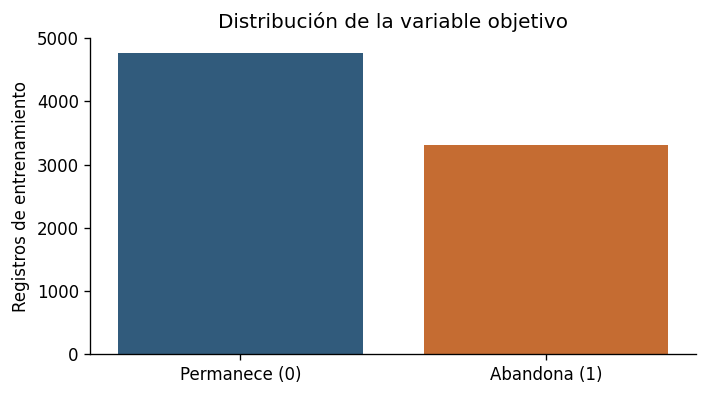

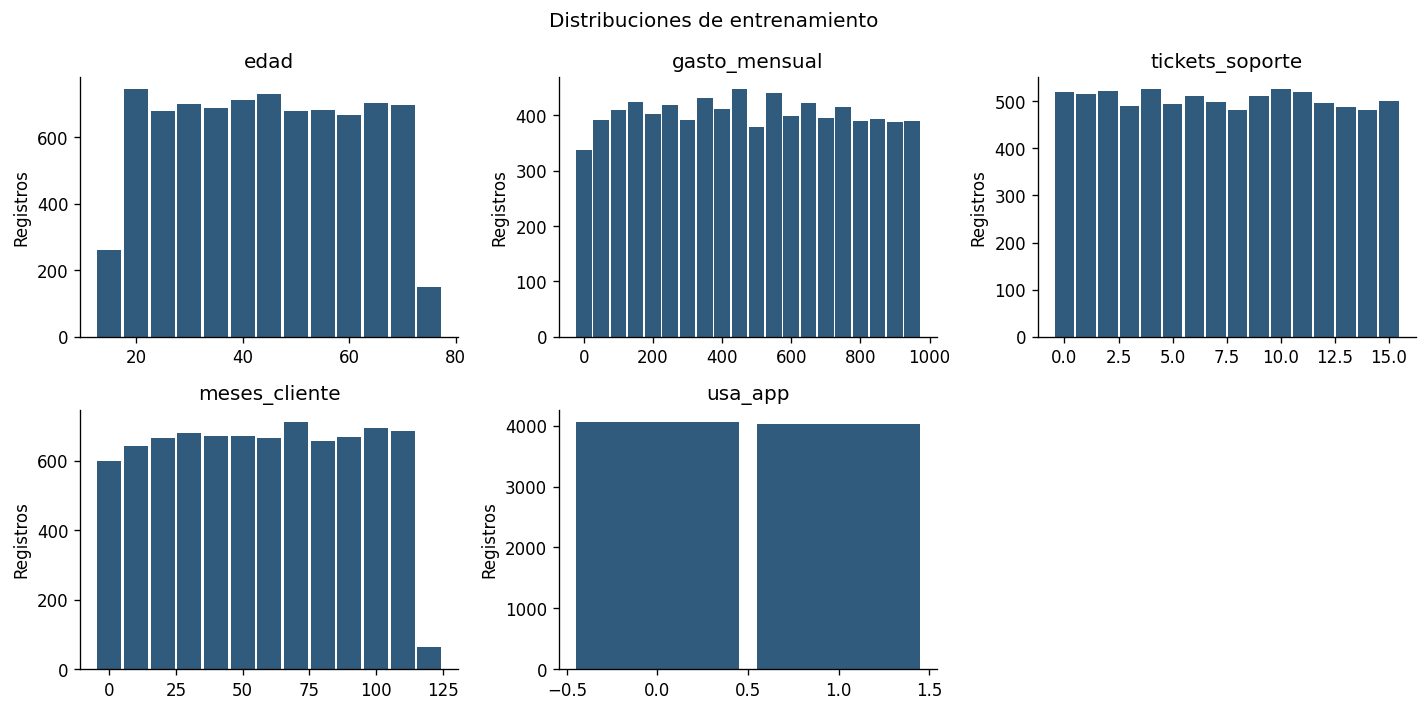

,edad,gasto_mensual,tickets_soporte,meses_cliente,usa_app,etiqueta
edad,1.000,-0.014,0.004,0.008,0.002,0.005
gasto_mensual,-0.014,1.000,0.009,-0.002,-0.014,0.177
tickets_soporte,0.004,0.009,1.000,-0.006,0.014,0.295
meses_cliente,0.008,-0.002,-0.006,1.000,0.002,-0.053
usa_app,0.002,-0.014,0.014,0.002,1.000,-0.011
etiqueta,0.005,0.177,0.295,-0.053,-0.011,1.000


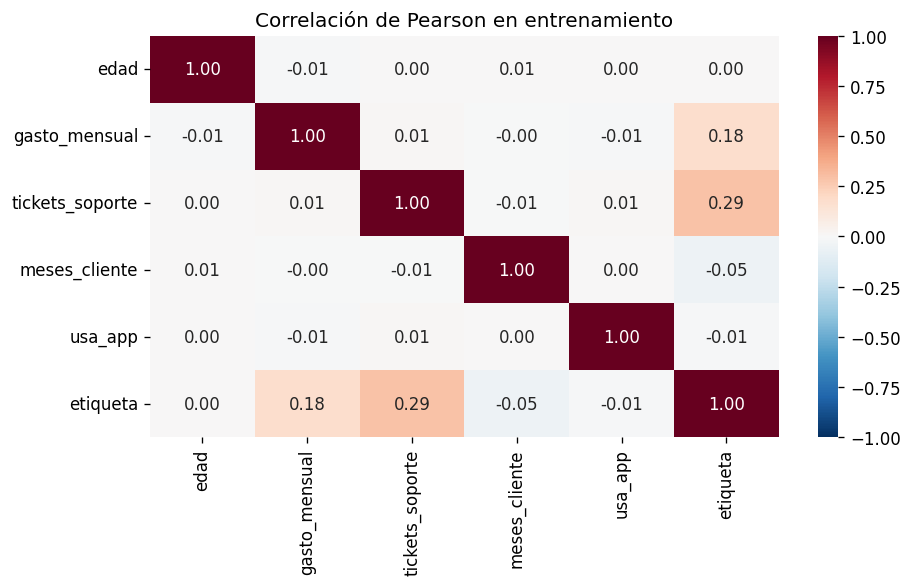

En entrenamiento, los abandonos representan **41.03%**. La asociación lineal más marcada con la etiqueta corresponde a **tickets_soporte** (r = **0.295**), seguida por **gasto_mensual** (r = **0.177**). Las correlaciones entre predictores son bajas en este archivo. El gasto, la antigüedad y las solicitudes están en escalas distintas, por lo que se estandarizan dentro del pipeline. Los valores extremos observados cumplen los dominios definidos y no se eliminan solamente por ser extremos. No hubo registros rechazados por las reglas de calidad; eso no prueba que estén libres de errores de origen.

In [5]:
descriptivas = entrenamiento.select(*(ATRIBUTOS + ["etiqueta"])).summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max").toPandas()
display(descriptivas)
descriptivas.to_csv(OUT / "descriptivas.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(["Permanece (0)", "Abandona (1)"], conteos_train["count"], color=["#315b7c", "#c56c32"])
ax.set(ylabel="Registros de entrenamiento", title="Distribución de la variable objetivo")
fig.tight_layout(); fig.savefig(OUT / "graficos/clases.png"); plt.show()
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
anchos = {"edad": 5, "gasto_mensual": 50, "tickets_soporte": 1, "meses_cliente": 10, "usa_app": 1}
for ax, atributo in zip(axes.flat, ATRIBUTOS):
    h = (entrenamiento.withColumn("intervalo", F.floor(F.col(atributo) / anchos[atributo]) * anchos[atributo])
         .groupBy("intervalo").count().orderBy("intervalo").toPandas())
    ax.bar(h["intervalo"], h["count"], width=anchos[atributo] * 0.9, color="#315b7c")
    ax.set(title=atributo, ylabel="Registros")
axes.flat[-1].axis("off")
fig.suptitle("Distribuciones de entrenamiento"); fig.tight_layout(); fig.savefig(OUT / "graficos/distribuciones.png"); plt.show()
columnas_corr = ATRIBUTOS + ["etiqueta"]
vectores = VectorAssembler(inputCols=columnas_corr, outputCol="correlacion").transform(entrenamiento)
matriz = Correlation.corr(vectores, "correlacion", "pearson").head()[0].toArray()
correlaciones = pd.DataFrame(matriz, index=columnas_corr, columns=columnas_corr)
display(correlaciones.round(3))
correlaciones.to_csv(OUT / "correlaciones.csv")
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación de Pearson en entrenamiento")
fig.tight_layout(); fig.savefig(OUT / "graficos/correlaciones.png"); plt.show()

proporcion = float(conteos_train.loc[conteos_train.etiqueta == 1, "count"].iloc[0]) / n_train
asociaciones = correlaciones["etiqueta"].drop("etiqueta").sort_values(key=abs, ascending=False)
display(Markdown(f"En entrenamiento, los abandonos representan **{proporcion:.2%}**. La asociación lineal más marcada con la etiqueta corresponde a **{asociaciones.index[0]}** (r = **{asociaciones.iloc[0]:.3f}**), seguida por **{asociaciones.index[1]}** (r = **{asociaciones.iloc[1]:.3f}**). Las correlaciones entre predictores son bajas en este archivo. El gasto, la antigüedad y las solicitudes están en escalas distintas, por lo que se estandarizan dentro del pipeline. Los valores extremos observados cumplen los dominios definidos y no se eliminan solamente por ser extremos. No hubo registros rechazados por las reglas de calidad; eso no prueba que estén libres de errores de origen."))


## 6 Estandarización y protocolo de comparación
Cada pipeline contiene VectorAssembler, StandardScaler con centrado y desviación estándar, y un clasificador. La regresión logística desactiva su estandarización interna para usar exclusivamente la etapa explícita del pipeline. El bosque recibe las mismas variables estandarizadas para mantener un recorrido comparable; su regla por umbrales no necesita la escala por la misma razón que la regresión regularizada.

El escalador se ajusta dentro de cada fold, sin usar su parte de validación ni la reserva final. En PostgreSQL conservo los atributos depurados en sus unidades originales. Los vectores son temporales de Spark ML.

| Modelo | Parámetros candidatos | Candidatos y ajustes |
|---|---|---|
| Regresión logística | regParam 0,01 y 0,1; elasticNetParam 0 y 0,5 | 4 candidatos por 4 folds |
| Bosque aleatorio | maxDepth 4 y 8; minInstancesPerNode 2 y 10; 40 árboles | 4 candidatos por 4 folds |

Selecciono cada combinación mediante AUC ROC media de los cuatro folds. La búsqueda incluye 32 ajustes de validación cruzada, más el reajuste de cada mejor pipeline sobre todo el entrenamiento. No se usa la reserva para ampliar la búsqueda.


In [6]:
ajustes = construir_validadores()
modelos = {}
resultados_cv = []
for especificacion in ajustes:
    nombre = especificacion["tabla"]
    print("Entrenando", especificacion["nombre"], flush=True)
    t = time.monotonic()
    cv_model = especificacion["validador"].fit(entrenamiento)
    filas = []
    for parametros, media, desviacion in zip(especificacion["parametros"], cv_model.avgMetrics, cv_model.stdMetrics):
        fila = {"modelo": nombre, **{p.name: v for p, v in parametros.items()}, "auc_cv_media": float(media), "auc_cv_desv": float(desviacion)}
        resultados_cv.append(fila); filas.append(fila)
    mejor_i = int(np.argmax(cv_model.avgMetrics))
    elegidos = {p.name: v for p, v in especificacion["parametros"][mejor_i].items()}
    modelos[nombre] = {"nombre": especificacion["nombre"], "pipeline": cv_model.bestModel,
                       "parametros": elegidos, "auc_cv": float(cv_model.avgMetrics[mejor_i]),
                       "desv_cv": float(cv_model.stdMetrics[mejor_i]), "segundos": time.monotonic() - t}
    cv_model.bestModel.write().overwrite().save(str(OUT / "modelos" / nombre))
    print("Elegidos:", elegidos, "AUC CV:", modelos[nombre]["auc_cv"])
    display(pd.DataFrame(filas))
pd.DataFrame(resultados_cv).to_csv(OUT / "validacion_cruzada.csv", index=False)


Entrenando Regresión logística


Elegidos: {'regParam': 0.01, 'elasticNetParam': 0.5} AUC CV: 0.700283946159476


,modelo,regParam,elasticNetParam,auc_cv_media,auc_cv_desv
0,modelo1,0.01,0.0,0.700085,0.004174
1,modelo1,0.01,0.5,0.700284,0.003610
2,modelo1,0.10,0.0,0.700144,0.004206
3,modelo1,0.10,0.5,0.696410,0.004138


Entrenando Bosque aleatorio


Elegidos: {'maxDepth': 4, 'minInstancesPerNode': 2} AUC CV: 0.699741253876441


,modelo,maxDepth,minInstancesPerNode,auc_cv_media,auc_cv_desv
0,modelo2,4,2,0.699741,0.008550
1,modelo2,4,10,0.699620,0.008509
2,modelo2,8,2,0.691377,0.008236
3,modelo2,8,10,0.695336,0.008430


## 7 Evidencia del escalado y evaluación de entrenamiento
Las medias y desviaciones del escalador corresponden al reajuste sobre entrenamiento. Las estadísticas transformadas permiten comprobar la estandarización. Las métricas siguientes describen el ajuste al entrenamiento y pueden ser optimistas; la comparación externa se hace después con la reserva.


In [7]:
scaler = modelos["modelo1"]["pipeline"].stages[1]
display(pd.DataFrame({"atributo": ATRIBUTOS, "media_aprendida": scaler.mean.toArray(), "desviacion_aprendida": scaler.std.toArray()}))
transformado = modelos["modelo1"]["pipeline"].transform(entrenamiento).withColumn("array_features", vector_to_array("features"))
escalado = transformado.select(*[F.col("array_features")[i].alias(c) for i, c in enumerate(ATRIBUTOS)])
display(escalado.summary("mean", "stddev").toPandas())
metricas_train = {k: evaluar(v["pipeline"].transform(entrenamiento)) for k, v in modelos.items()}
display(pd.DataFrame(metricas_train).T)


,atributo,media_aprendida,desviacion_aprendida
0,edad,46.418121,16.773433
1,gasto_mensual,500.924654,283.681900
2,tickets_soporte,7.441267,4.610663
3,meses_cliente,60.901597,34.613615
4,usa_app,0.497339,0.500024


,summary,edad,gasto_mensual,tickets_soporte,meses_cliente,usa_app
0,mean,9.96034545842878E-15,-1.950874444317037E-15,4.986755187795842E-15,1.623696020232521E-15,7.851677526300649E-16
1,stddev,0.9999999999999983,0.9999999999999994,1.0000000000000009,1.0000000000000009,1.0000000000000016


,n,auc_roc,auc_pr,accuracy,precision_positiva,recall_positivo,f1_positivo,tn,fp,fn,tp
modelo1,8079.0,0.700927,0.606906,0.658126,0.610467,0.460935,0.525266,3789.0,975.0,1787.0,1528.0
modelo2,8079.0,0.711509,0.628398,0.665181,0.648926,0.400905,0.495618,4045.0,719.0,1986.0,1329.0


## 8 Evaluación final y predicciones en PostgreSQL
Con los dos pipelines y sus parámetros ya elegidos, evalúo la misma reserva final. La clase positiva es abandono, 1. Precision mide cuántos abandonos predichos son correctos; recall mide cuántos abandonos reales se detectan. F1 es el de la clase positiva, no el promedio ponderado entre clases. AUC ROC y AUC PR usan las puntuaciones, mientras la matriz de confusión usa el umbral fijo 0,5.

Persisto solo las filas de reserva, las siete columnas de `tarea3` y `prediccion` entera. No escribo features, probability, rawPrediction ni fold en las tablas de predicción.


,modelo,nombre,auc_cv,n,auc_roc,auc_pr,accuracy,precision_positiva,recall_positivo,f1_positivo,tn,fp,fn,tp
0,modelo1,Regresión logística,0.700284,1921,0.718064,0.624197,0.671005,0.638095,0.498759,0.559889,887,228,404,402
1,modelo2,Bosque aleatorio,0.699741,1921,0.719647,0.629872,0.665279,0.656430,0.424318,0.515448,936,179,464,342


Referencia de clase mayoritaria: 0 Accuracy final: 0.5804


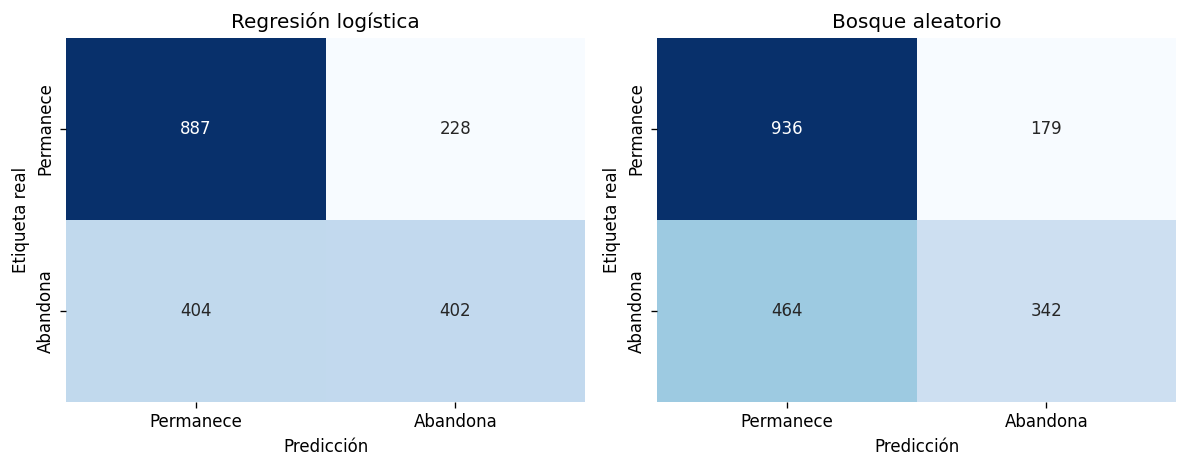

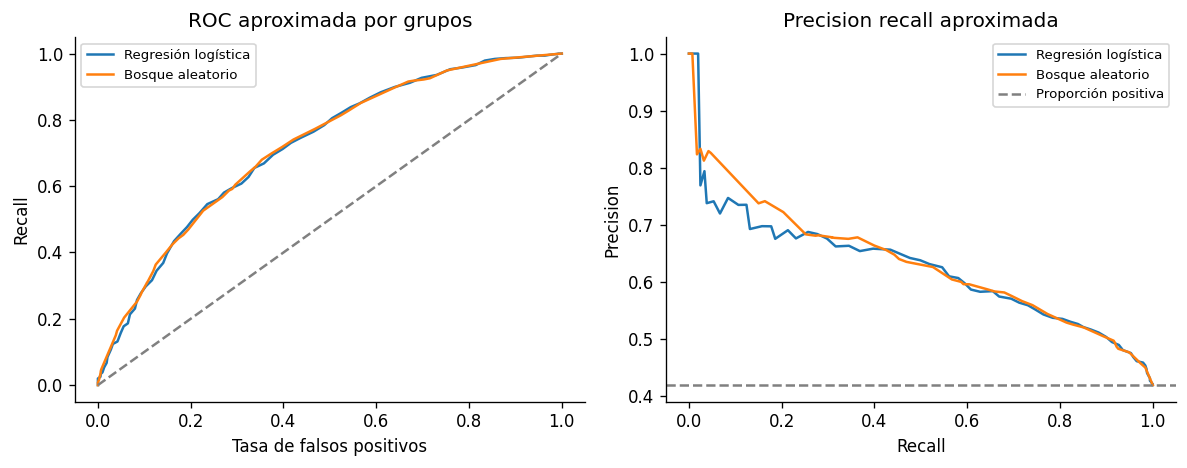

In [8]:
metricas_final = {}
curvas = {}
predicciones_sql = {}
for k, v in modelos.items():
    pred = v["pipeline"].transform(reserva).cache()
    pred.count()
    metricas_final[k] = evaluar(pred)
    curvas[k] = curvas_agrupadas(pred)
    tabla = tabla_predicciones(pred).cache()
    tabla.count()
    escribir_tabla(tabla, k)
    predicciones_sql[k] = tabla
    pred.unpersist()
mayoritaria = int(conteos_train.sort_values(["count", "etiqueta"], ascending=[False, True]).iloc[0]["etiqueta"])
accuracy_base = reserva.filter(F.col("etiqueta") == mayoritaria).count() / n_final
comparacion = pd.DataFrame([{ "modelo": k, "nombre": modelos[k]["nombre"], "auc_cv": modelos[k]["auc_cv"], **m} for k, m in metricas_final.items()])
display(comparacion)
print("Referencia de clase mayoritaria:", mayoritaria, "Accuracy final:", round(accuracy_base, 4))
comparacion.to_csv(OUT / "comparacion_modelos.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (k, m) in zip(axes, metricas_final.items()):
    sns.heatmap([[m["tn"], m["fp"]], [m["fn"], m["tp"]]], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Permanece", "Abandona"], yticklabels=["Permanece", "Abandona"])
    ax.set(title=modelos[k]["nombre"], xlabel="Predicción", ylabel="Etiqueta real")
fig.tight_layout(); fig.savefig(OUT / "graficos/matrices_confusion.png"); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for k, grupos in curvas.items():
    pos = sum(g["positivos"] for g in grupos); neg = sum(g["negativos"] for g in grupos)
    tp = np.cumsum([g["positivos"] for g in grupos]); fp = np.cumsum([g["negativos"] for g in grupos])
    axes[0].plot(np.r_[0, fp / neg], np.r_[0, tp / pos], label=modelos[k]["nombre"])
    axes[1].plot(np.r_[0, tp / pos], np.r_[1, tp / (tp + fp)], label=modelos[k]["nombre"])
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(title="ROC aproximada por grupos", xlabel="Tasa de falsos positivos", ylabel="Recall")
axes[1].axhline(pos / (pos + neg), linestyle="--", color="gray", label="Proporción positiva")
axes[1].set(title="Precision recall aproximada", xlabel="Recall", ylabel="Precision")
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "graficos/curvas.png"); plt.show()


## 9 Comprobación de persistencia y repetición de cargas
Verifico contenido, columnas e identificadores de las tres tablas mediante Spark JDBC. Después repito la escritura de las mismas tres tablas con overwrite y vuelvo a comprobarlas: la repetición debe conservar datos y conteos. Esta prueba no vuelve a entrenar modelos ni consulta la reserva para ajustar parámetros.


In [9]:
verificacion_antes = comprobar_tablas(spark, base, reserva, predicciones_sql["modelo1"], predicciones_sql["modelo2"])
escribir_tabla(limpio, "tarea3")
for k, df_sql in predicciones_sql.items():
    escribir_tabla(df_sql, k)
verificacion = comprobar_tablas(spark, limpio, reserva, predicciones_sql["modelo1"], predicciones_sql["modelo2"])
assert verificacion == verificacion_antes
print("Repetición de las tres cargas: mismos contenidos y conteos")
display(pd.DataFrame([{ "tabla": k, **v} for k, v in verificacion.items()]))
for nombre in ["tarea3", "modelo1", "modelo2"]:
    display(leer_tabla(spark, nombre).orderBy("id").limit(5).toPandas())


Repetición de las tres cargas: mismos contenidos y conteos


,tabla,filas,columnas,diferencias
0,tarea3,10000,"[id, edad, gasto_mensual, tickets_soporte, mes...",0
1,modelo1,1921,"[id, edad, gasto_mensual, tickets_soporte, mes...",0
2,modelo2,1921,"[id, edad, gasto_mensual, tickets_soporte, mes...",0


,id,edad,gasto_mensual,tickets_soporte,meses_cliente,usa_app,etiqueta
0,0008d2a2-0ae0-4b3c-b36c-f9147dd882f3,74,201.12,0,76,0,0
1,00252802-99db-4397-8dd7-225759abe10f,44,750.38,15,102,1,0
2,003911c8-38d7-4ed2-82ae-b732aaa3de99,34,927.91,6,105,1,0
3,003c1d64-9f0e-4ffa-89e2-d7734b72d3c9,34,472.89,9,15,0,0
4,00415e95-dc8e-40d5-86a7-55a2d473536a,75,267.08,3,89,0,0


,id,edad,gasto_mensual,tickets_soporte,meses_cliente,usa_app,etiqueta,prediccion
0,003911c8-38d7-4ed2-82ae-b732aaa3de99,34,927.91,6,105,1,0,0
1,00450712-037b-4d24-b43b-4ba216e8078b,60,780.92,7,87,0,1,0
2,004b2c95-716f-4a28-af84-1d182624e5f8,26,434.93,13,62,1,0,1
3,0087d923-7cdf-48db-97ca-43cf01b68fdd,62,664.24,1,15,0,0,0
4,008c771e-10d1-4368-8644-93c5b035d9a7,52,449.20,1,52,1,0,0


,id,edad,gasto_mensual,tickets_soporte,meses_cliente,usa_app,etiqueta,prediccion
0,003911c8-38d7-4ed2-82ae-b732aaa3de99,34,927.91,6,105,1,0,0
1,00450712-037b-4d24-b43b-4ba216e8078b,60,780.92,7,87,0,1,0
2,004b2c95-716f-4a28-af84-1d182624e5f8,26,434.93,13,62,1,0,0
3,0087d923-7cdf-48db-97ca-43cf01b68fdd,62,664.24,1,15,0,0,0
4,008c771e-10d1-4368-8644-93c5b035d9a7,52,449.20,1,52,1,0,0


## 10 Interpretación y comparación de resultados
Los coeficientes de la regresión logística se expresan sobre atributos estandarizados. Sus signos describen asociación condicional en este modelo, no causalidad. Las importancias del bosque son internas al modelo y no equivalen a esos coeficientes. La comparación utiliza las mismas observaciones finales y se presenta sin reajustar el umbral ni ampliar la búsqueda tras ver la reserva.


In [10]:
coeficientes = modelos["modelo1"]["pipeline"].stages[-1].coefficients.toArray()
importancias = modelos["modelo2"]["pipeline"].stages[-1].featureImportances.toArray()
explicacion = pd.DataFrame({"atributo": ATRIBUTOS, "coeficiente_logistico": coeficientes, "importancia_bosque": importancias})
display(explicacion)
explicacion.to_csv(OUT / "atributos_modelos.csv", index=False)
a, b = metricas_final["modelo1"], metricas_final["modelo2"]
mejor = max(metricas_final, key=lambda k: metricas_final[k]["auc_roc"])
importante = ATRIBUTOS[int(np.argmax(importancias))]
texto = f"""
La regresión logística obtuvo AUC ROC **{a['auc_roc']:.4f}** y F1 positivo **{a['f1_positivo']:.4f}** en reserva.
El bosque obtuvo AUC ROC **{b['auc_roc']:.4f}** y F1 positivo **{b['f1_positivo']:.4f}**. La diferencia de AUC del bosque respecto a la regresión fue **{b['auc_roc']-a['auc_roc']:+.4f}**.

La mayor AUC final correspondió a **{modelos[mejor]['nombre']}**. Sus resultados describen esta reserva y no son una prueba de superioridad universal ni de significación estadística. La referencia que predice siempre la clase {mayoritaria} alcanzó accuracy **{accuracy_base:.4f}**; compararla con ambas matrices ayuda a no confundir la proporción de aciertos con la detección de abandonos.

La regresión dejó sin detectar **{a['fn']}** abandonos y generó **{a['fp']}** falsas alertas; el bosque dejó **{b['fn']}** sin detectar y produjo **{b['fp']}** falsas alertas. Estos errores tienen implicaciones distintas: perder un abandono y contactar innecesariamente a un cliente. No se dispone de costos de negocio para convertir esa diferencia en una decisión operativa.

El atributo de mayor importancia interna del bosque fue **{importante}**. El bosque puede representar umbrales e interacciones; la regresión ajusta un efecto aditivo sobre el logaritmo de las probabilidades relativas. Esto ofrece una explicación posible de diferencias de desempeño, pero el archivo no documenta su mecanismo de generación y no permite afirmar que la relación encontrada sea causal o representativa de clientes reales.

La AUC de entrenamiento fue **{metricas_train['modelo1']['auc_roc']:.4f}** para la regresión y **{metricas_train['modelo2']['auc_roc']:.4f}** para el bosque; sus medias de CV fueron **{modelos['modelo1']['auc_cv']:.4f}** y **{modelos['modelo2']['auc_cv']:.4f}**, con desviaciones entre folds de **{modelos['modelo1']['desv_cv']:.4f}** y **{modelos['modelo2']['desv_cv']:.4f}**. La diferencia entrenamiento-CV es mayor en el bosque y sugiere mayor optimismo de ajuste. Que la reserva obtenga una AUC superior a CV puede deberse a la variación de la partición; no demuestra un beneficio de generalización.

Con el umbral fijado, la regresión tiene mayor recall y F1 positivo en esta reserva y sería la opción a considerar si el propósito prioriza detectar abandonos. El bosque tiene mayor precision y genera menos falsas alertas. La ventaja de AUC del bosque es pequeña y no basta para preferirlo en cualquier uso. Ninguno detecta más de la mitad de los abandonos con este umbral. La AUC PR se contrasta con la proporción positiva de reserva (**{float(conteos_final.loc[conteos_final.etiqueta == 1, 'count'].iloc[0]) / n_final:.4f}**), que sirve como referencia de precisión para una clasificación sin información. No se reajusta el umbral tras observar estos resultados. Hay cuatro candidatos por modelo y cuatro folds; no es una búsqueda exhaustiva. La partición es por registros de ID único y no evalúa cambios temporales o traslados a otra población. La reserva se utilizó para la evaluación final y no para volver a elegir parámetros.
"""
display(Markdown(texto))
(OUT / "Analisis_resultados.md").write_text(texto)


,atributo,coeficiente_logistico,importancia_bosque
0,edad,0.000000,0.010622
1,gasto_mensual,0.361298,0.237428
2,tickets_soporte,0.610272,0.644415
3,meses_cliente,-0.089685,0.107338
4,usa_app,-0.006764,0.000198



La regresión logística obtuvo AUC ROC **0.7181** y F1 positivo **0.5599** en reserva.
El bosque obtuvo AUC ROC **0.7196** y F1 positivo **0.5154**. La diferencia de AUC del bosque respecto a la regresión fue **+0.0016**.

La mayor AUC final correspondió a **Bosque aleatorio**. Sus resultados describen esta reserva y no son una prueba de superioridad universal ni de significación estadística. La referencia que predice siempre la clase 0 alcanzó accuracy **0.5804**; compararla con ambas matrices ayuda a no confundir la proporción de aciertos con la detección de abandonos.

La regresión dejó sin detectar **404** abandonos y generó **228** falsas alertas; el bosque dejó **464** sin detectar y produjo **179** falsas alertas. Estos errores tienen implicaciones distintas: perder un abandono y contactar innecesariamente a un cliente. No se dispone de costos de negocio para convertir esa diferencia en una decisión operativa.

El atributo de mayor importancia interna del bosque fue **tickets_soporte**. El bosque puede representar umbrales e interacciones; la regresión ajusta un efecto aditivo sobre el logaritmo de las probabilidades relativas. Esto ofrece una explicación posible de diferencias de desempeño, pero el archivo no documenta su mecanismo de generación y no permite afirmar que la relación encontrada sea causal o representativa de clientes reales.

La AUC de entrenamiento fue **0.7009** para la regresión y **0.7115** para el bosque; sus medias de CV fueron **0.7003** y **0.6997**, con desviaciones entre folds de **0.0036** y **0.0086**. La diferencia entrenamiento-CV es mayor en el bosque y sugiere mayor optimismo de ajuste. Que la reserva obtenga una AUC superior a CV puede deberse a la variación de la partición; no demuestra un beneficio de generalización.

Con el umbral fijado, la regresión tiene mayor recall y F1 positivo en esta reserva y sería la opción a considerar si el propósito prioriza detectar abandonos. El bosque tiene mayor precision y genera menos falsas alertas. La ventaja de AUC del bosque es pequeña y no basta para preferirlo en cualquier uso. Ninguno detecta más de la mitad de los abandonos con este umbral. La AUC PR se contrasta con la proporción positiva de reserva (**0.4196**), que sirve como referencia de precisión para una clasificación sin información. No se reajusta el umbral tras observar estos resultados. Hay cuatro candidatos por modelo y cuatro folds; no es una búsqueda exhaustiva. La partición es por registros de ID único y no evalúa cambios temporales o traslados a otra población. La reserva se utilizó para la evaluación final y no para volver a elegir parámetros.


2643

## 11 Resumen reproducible y fuentes
El resumen JSON conserva la identidad del archivo, versiones, separación, calidad, parámetros, métricas y verificaciones. Las fuentes de clase son el enunciado T3; `Binary classification.ipynb` y la configuración L5/T3; L5, `video1324764996.mp4`, 00:00–00:11:10; y L4, `video1908915064.mp4`, 00:28:30–00:38:30 y 01:04:30–01:07:30 para conectores y Spark ML. Las API consultadas de Apache Spark se detallan en `doc/Fuentes.md`.


In [11]:
resumen = {
    "fecha_ejecucion": datetime.now(ZoneInfo("America/Costa_Rica")).isoformat(),
    "versiones": {"python": platform.python_version(), "spark": spark.version, "jdbc": "42.7.3"},
    "fuente": fuente, "calidad": calidad,
    "particion": {"entrenamiento": n_train, "reserva": n_final, "semilla": SEMILLA, "folds": FOLDS},
    "clase_mayoritaria": mayoritaria, "accuracy_referencia": accuracy_base,
    "modelos": {k: {kk: vv for kk, vv in v.items() if kk != "pipeline"} for k, v in modelos.items()},
    "metricas_entrenamiento": metricas_train, "metricas_reserva": metricas_final,
    "validacion_cruzada": resultados_cv, "verificacion_sql": verificacion,
    "repeticion_overwrite_verificada": True,
    "atributos_modelos": explicacion.to_dict("records"),
    "segundos_totales": time.monotonic() - inicio,
}
(OUT / "Resumen_ejecucion.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=2))
print(json.dumps({"calidad": calidad, "particion": resumen["particion"], "metricas_reserva": metricas_final, "segundos": resumen["segundos_totales"]}, ensure_ascii=False, indent=2))
for df_cache in [limpio, base, entrenamiento, reserva, *predicciones_sql.values()]:
    df_cache.unpersist()
spark.stop()
print("Ejecución terminada y tablas verificadas")


{
  "calidad": {
    "filas_entrada": 10000,
    "filas_validas_antes_duplicados": 10000,
    "filas_unicas_validas": 10000,
    "identificadores_conflictivos": 0,
    "filas_limpias": 10000,
    "filas_invalidas": 0,
    "duplicados_exactos_eliminados": 0,
    "filas_conflictivas_eliminadas": 0
  },
  "particion": {
    "entrenamiento": 8079,
    "reserva": 1921,
    "semilla": 27,
    "folds": 4
  },
  "metricas_reserva": {
    "modelo1": {
      "n": 1921,
      "auc_roc": 0.7180640710367341,
      "auc_pr": 0.6241965213294796,
      "accuracy": 0.6710046850598647,
      "precision_positiva": 0.638095238095238,
      "recall_positivo": 0.4987593052109181,
      "f1_positivo": 0.5598885793871866,
      "tn": 887,
      "fp": 228,
      "fn": 404,
      "tp": 402
    },
    "modelo2": {
      "n": 1921,
      "auc_roc": 0.7196469305322192,
      "auc_pr": 0.6298724762911503,
      "accuracy": 0.6652785007808433,
      "precision_positiva": 0.6564299424184261,
      "recall_positivo": 

Ejecución terminada y tablas verificadas
